In [1]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd
# Libraries to help with data visualization
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection  import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
# to scale the data using z-score
from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler
# to compute distances
from scipy.spatial.distance import pdist
# to perform hierarchical clustering, compute cophenetic correlation, and create dendrograms
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
# to perform PCA
from sklearn.decomposition import PCA
# to ignore unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

In [2]:
from google.colab import files
uploaded = files.upload()

Saving Credit Card Customer Data.xlsx to Credit Card Customer Data.xlsx


In [3]:
df = pd.read_excel("Credit Card Customer Data.xlsx")

In [4]:
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [5]:
df.shape

(660, 7)

In [6]:
df.info() # Display information about columns, data types, and non-null values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [7]:
df.isnull().sum() # Check missing values in each column

,0
Sl_No,0
Customer Key,0
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


In [8]:
# Generate summary statistics for numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Sl_No,660.0,330.500000,190.669872,1.0,165.75,330.5,495.25,660.0
Customer Key,660.0,55141.443939,25627.772200,11265.0,33825.25,53874.5,77202.50,99843.0
Avg_Credit_Limit,660.0,34574.242424,37625.487804,3000.0,10000.00,18000.0,48000.00,200000.0
Total_Credit_Cards,660.0,4.706061,2.167835,1.0,3.00,5.0,6.00,10.0
Total_visits_bank,660.0,2.403030,1.631813,0.0,1.00,2.0,4.00,5.0
Total_visits_online,660.0,2.606061,2.935724,0.0,1.00,2.0,4.00,15.0
Total_calls_made,660.0,3.583333,2.865317,0.0,1.00,3.0,5.00,10.0


In [9]:
df.isnull().sum() # Check missing values in each column

,0
Sl_No,0
Customer Key,0
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


In [10]:
df.duplicated().sum() # Check the number of duplicate rows in the dataset

np.int64(0)

In [11]:
df.nunique() # Check the number of unique values in each column

,0
Sl_No,660
Customer Key,655
Avg_Credit_Limit,110
Total_Credit_Cards,10
Total_visits_bank,6
Total_visits_online,16
Total_calls_made,11


### Observations from Basic Data Understanding

- The dataset has 660 rows and 7 columns.
- There are no missing values.
- There are no duplicate rows.
- Sl_No and Customer Key are identifier columns.
- The main variables useful for clustering are:
  - Avg_Credit_Limit
  - Total_Credit_Cards
  - Total_visits_bank
  - Total_visits_online
  - Total_calls_made

##Univariate Analysis

In [12]:
eda_cols = [       # Create a list of numerical columns useful for EDA and clustering
    "Avg_Credit_Limit",
    "Total_Credit_Cards",
    "Total_visits_bank",
    "Total_visits_online",
    "Total_calls_made"
]

In [13]:
df[eda_cols].describe().T # Display descriptive statistics for selected numerical columns

,count,mean,std,min,25%,50%,75%,max
Avg_Credit_Limit,660.0,34574.242424,37625.487804,3000.0,10000.0,18000.0,48000.0,200000.0
Total_Credit_Cards,660.0,4.706061,2.167835,1.0,3.0,5.0,6.0,10.0
Total_visits_bank,660.0,2.403030,1.631813,0.0,1.0,2.0,4.0,5.0
Total_visits_online,660.0,2.606061,2.935724,0.0,1.0,2.0,4.0,15.0
Total_calls_made,660.0,3.583333,2.865317,0.0,1.0,3.0,5.0,10.0


In [14]:
df[eda_cols].skew() # Check skewness for selected numerical columns

,0
Avg_Credit_Limit,2.202396
Total_Credit_Cards,0.144879
Total_visits_bank,0.141896
Total_visits_online,2.225607
Total_calls_made,0.658905


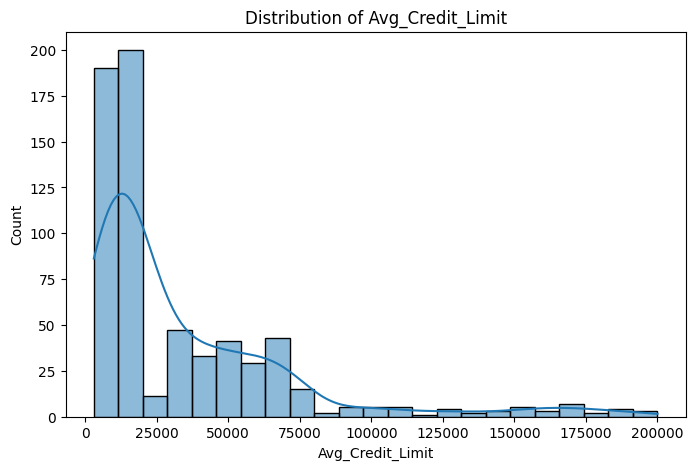

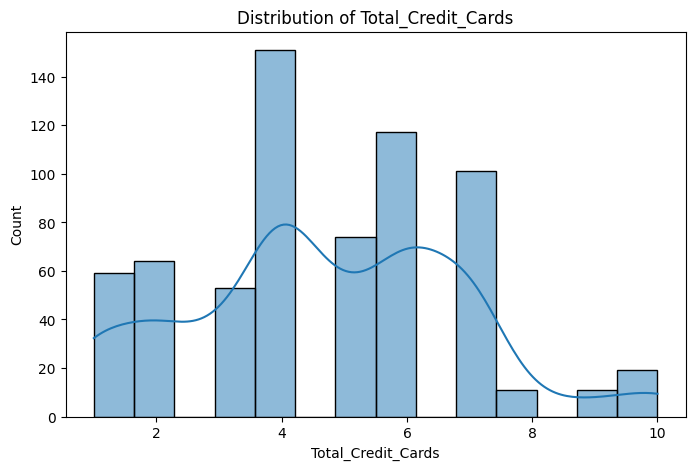

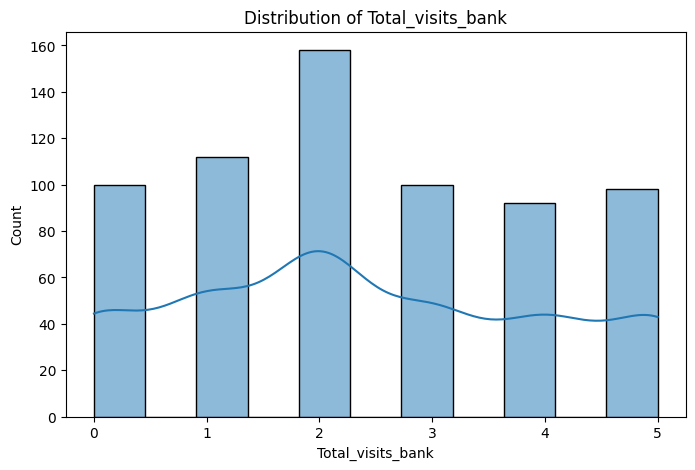

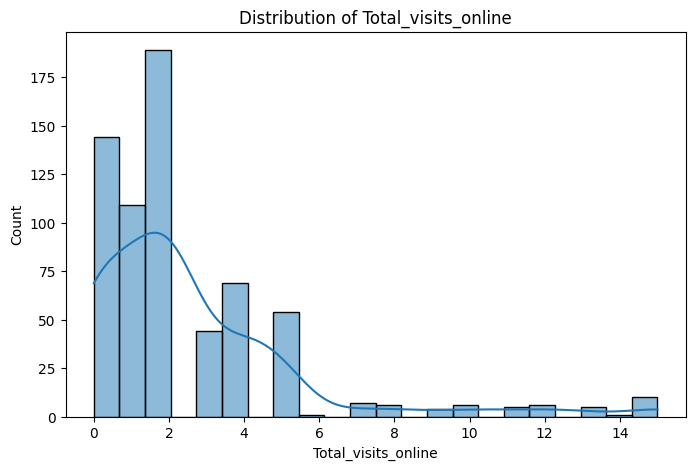

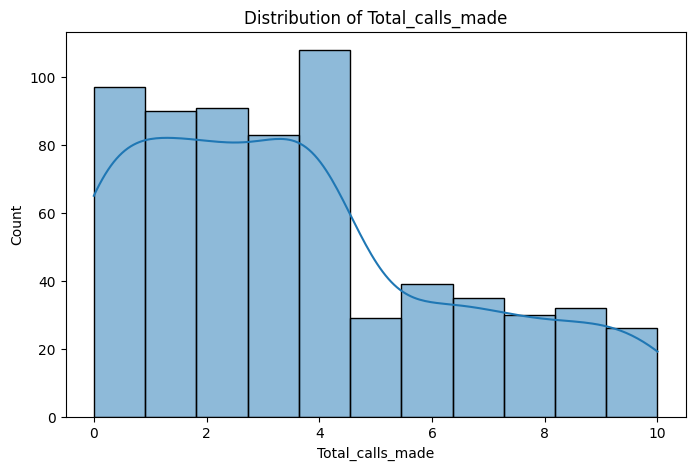

In [15]:
for col in eda_cols:   # Create histogram plots for each numerical variable

    plt.figure(figsize=(8, 5)) # Create a new figure for the plot
    sns.histplot(data=df, x=col, kde=True) # Plot histogram with KDE curve
    # Add title to the plot
    plt.title(f"Distribution of {col}")
    # Add x-axis label
    plt.xlabel(col)
    # Add y-axis label
    plt.ylabel("Count")
    # Display the plot
    plt.show()

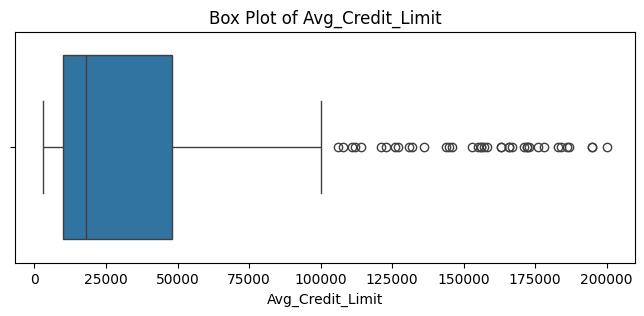

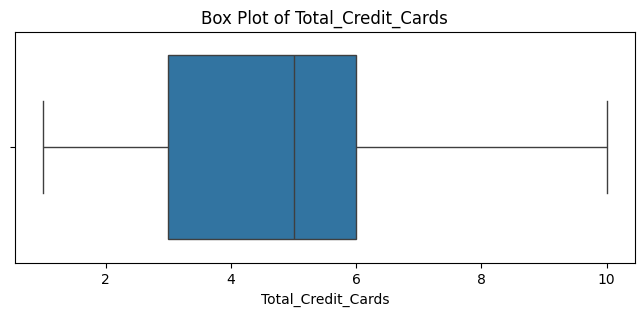

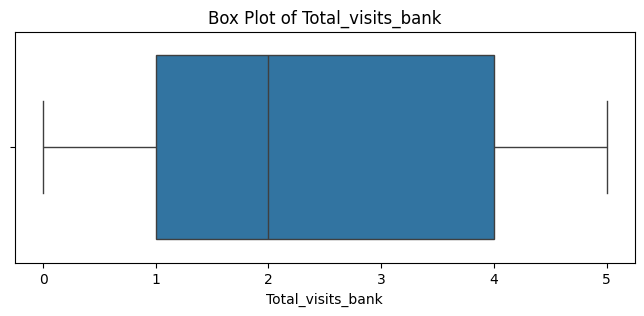

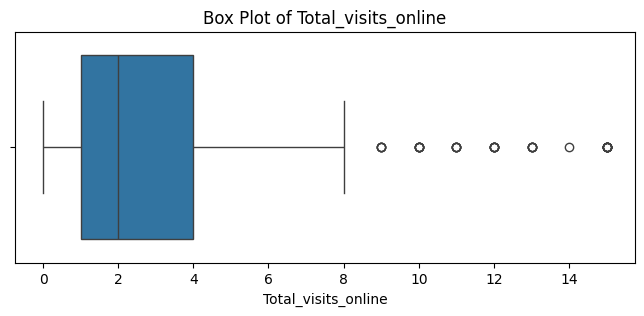

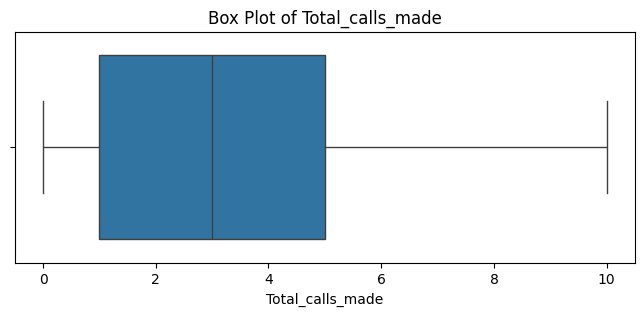

In [16]:
# Create box plots for each numerical variable
for col in eda_cols:
    # Create a new figure for the box plot
    plt.figure(figsize=(8, 3))
    # Plot box plot for the selected column
    sns.boxplot(data=df, x=col)
    # Add title to the plot
    plt.title(f"Box Plot of {col}")
    # Add x-axis label
    plt.xlabel(col)
    # Display the plot
    plt.show()

##Key Meaningful Observations on Individual Variables

- Avg_Credit_Limit is highly right-skewed. Most customers have low to moderate credit limits, while a smaller group has very high credit limits.
- Total_Credit_Cards ranges from 1 to 10. Most customers have around 4 to 6 credit cards.
- Total_visits_bank ranges from 0 to 5. Most customers visit the bank a small number of times per year.
- Total_visits_online is right-skewed. Most customers have low online activity, but a few customers use online banking very frequently.
- Total_calls_made ranges from 0 to 10. Some customers contact customer service much more frequently than others.

## Bivariate Analysis

In [17]:
# Calculate correlation matrix for selected numerical variables
corr = df[eda_cols].corr()
# Display the correlation matrix
corr

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Avg_Credit_Limit,1.000000,0.608860,-0.100312,0.551385,-0.414352
Total_Credit_Cards,0.608860,1.000000,0.315796,0.167758,-0.651251
Total_visits_bank,-0.100312,0.315796,1.000000,-0.551861,-0.506016
Total_visits_online,0.551385,0.167758,-0.551861,1.000000,0.127299
Total_calls_made,-0.414352,-0.651251,-0.506016,0.127299,1.000000


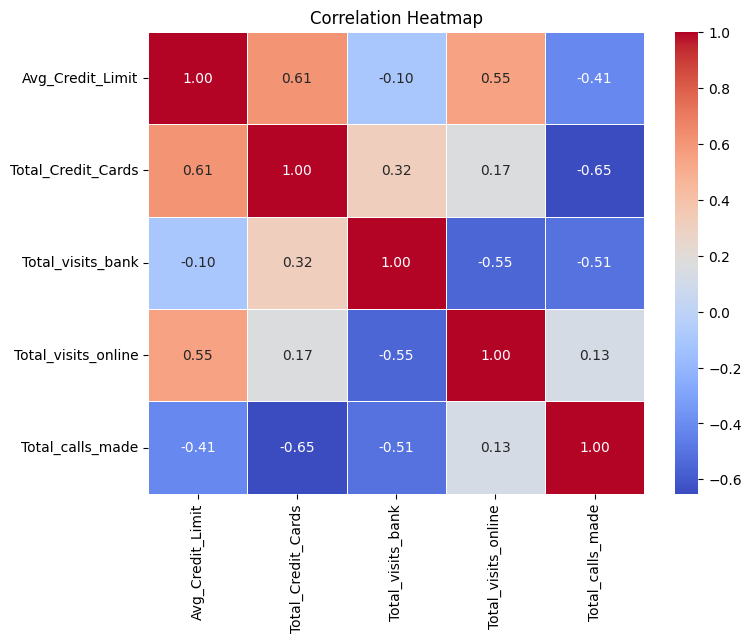

In [18]:
# Create a figure for the correlation heatmap
plt.figure(figsize=(8, 6))
# Plot correlation heatmap with values
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
# Add title to the heatmap
plt.title("Correlation Heatmap")
# Display the heatmap
plt.show()

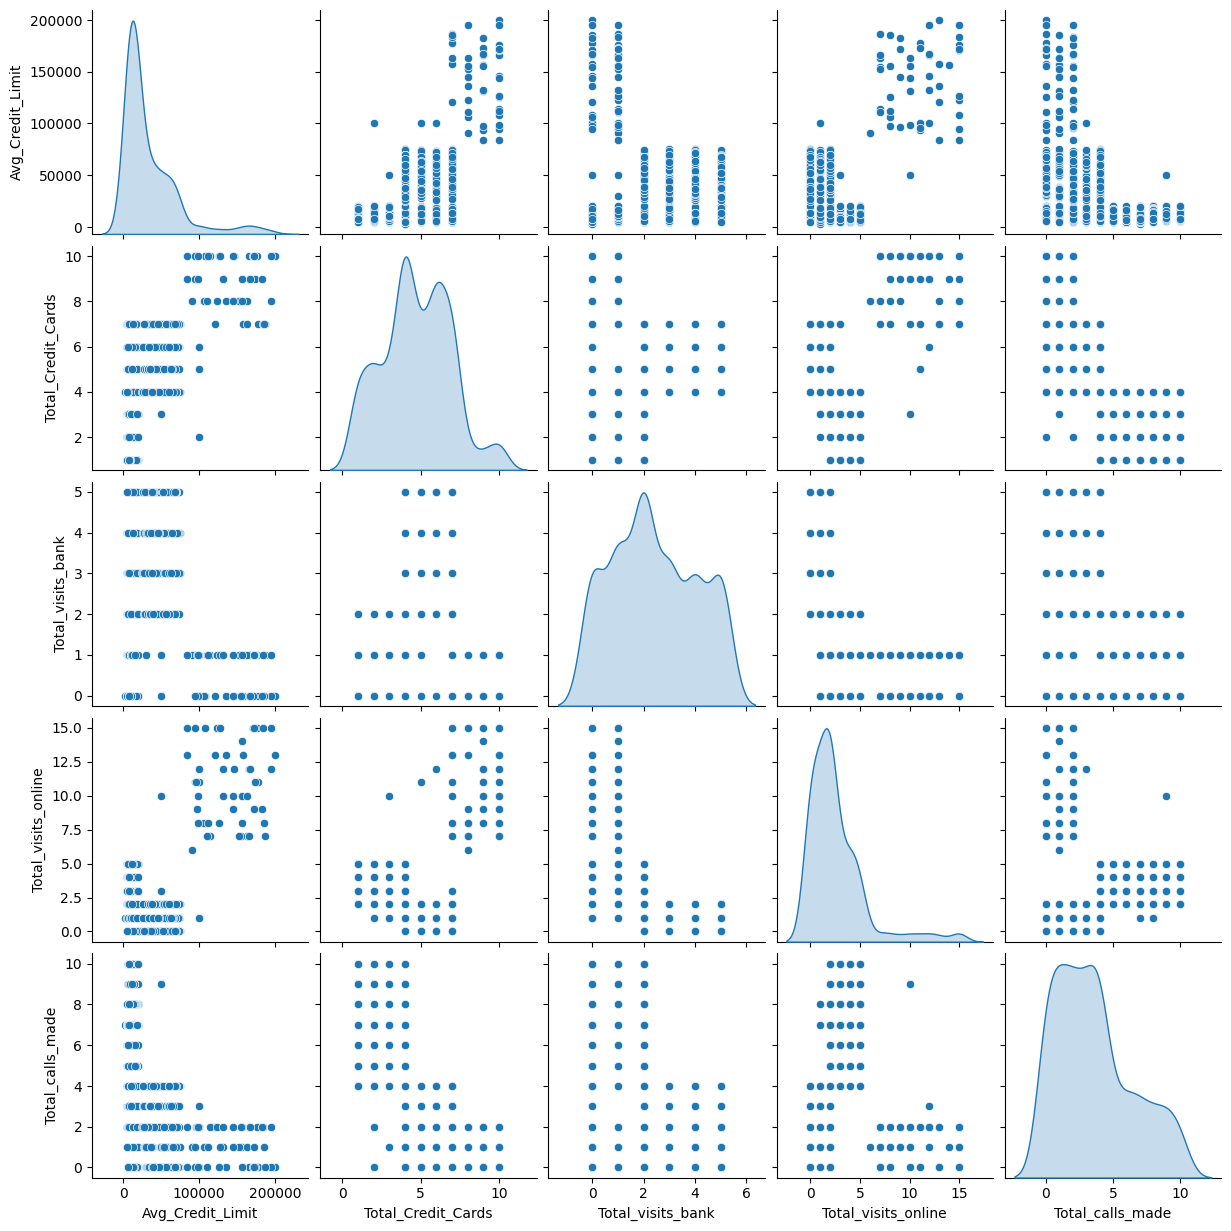

In [19]:
# Create pair plot for selected numerical variables
sns.pairplot(df[eda_cols], diag_kind="kde")
# Display the pair plot
plt.show()

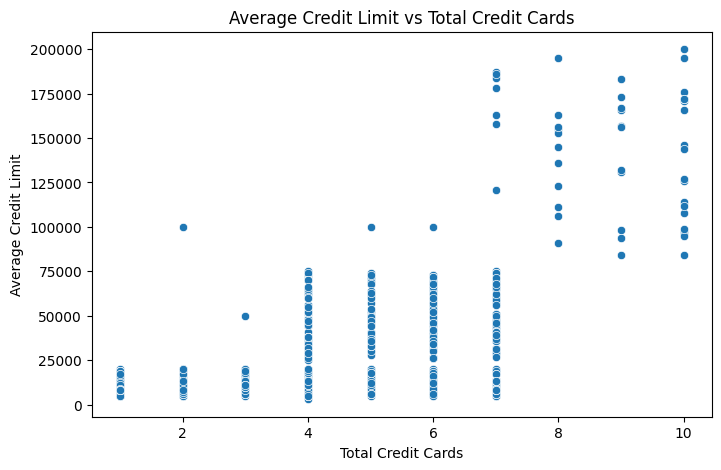

In [20]:
# Create figure for credit limit and total credit cards relationship
plt.figure(figsize=(8, 5))
# Create scatter plot
sns.scatterplot(data=df, x="Total_Credit_Cards", y="Avg_Credit_Limit")
# Add title
plt.title("Average Credit Limit vs Total Credit Cards")
# Add x-axis label
plt.xlabel("Total Credit Cards")
# Add y-axis label
plt.ylabel("Average Credit Limit")
# Display plot
plt.show()

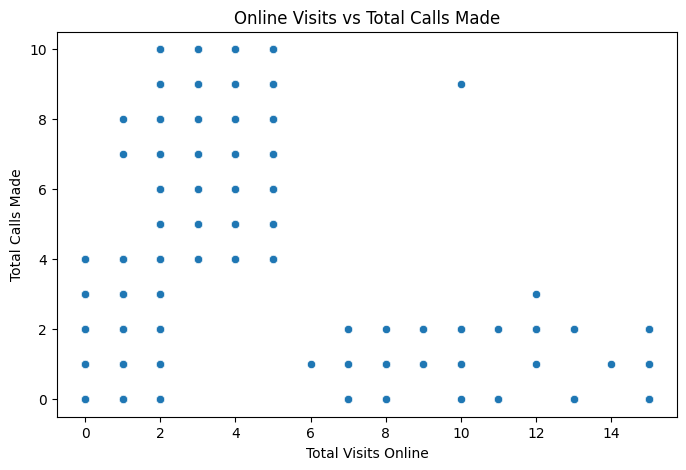

In [21]:
# Create figure for online visits and calls made relationship
plt.figure(figsize=(8, 5))
# Create scatter plot
sns.scatterplot(data=df, x="Total_visits_online", y="Total_calls_made")
# Add title
plt.title("Online Visits vs Total Calls Made")
# Add x-axis label
plt.xlabel("Total Visits Online")
# Add y-axis label
plt.ylabel("Total Calls Made")
# Display plot
plt.show()

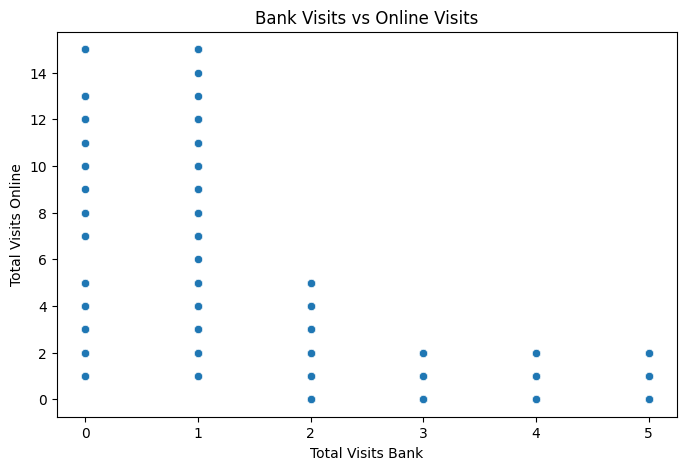

In [22]:
# Create figure for bank visits and online visits relationship
plt.figure(figsize=(8, 5))
# Create scatter plot
sns.scatterplot(data=df, x="Total_visits_bank", y="Total_visits_online")
# Add title
plt.title("Bank Visits vs Online Visits")
# Add x-axis label
plt.xlabel("Total Visits Bank")
# Add y-axis label
plt.ylabel("Total Visits Online")
# Display plot
plt.show()

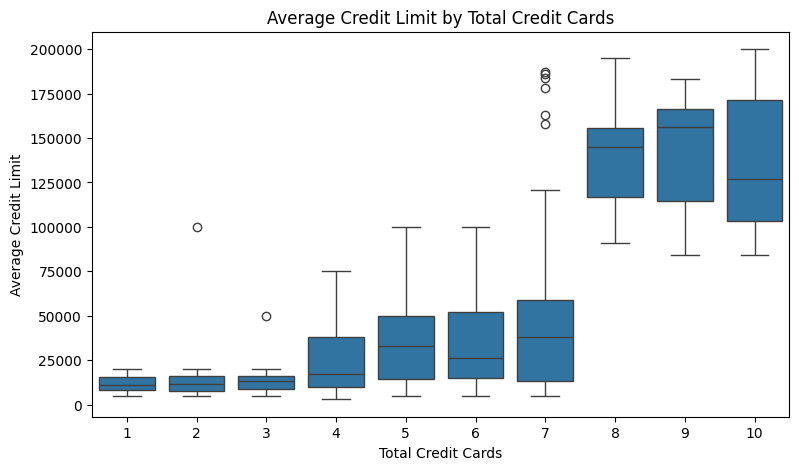

In [23]:
# Create figure for average credit limit by total credit cards
plt.figure(figsize=(9, 5))
# Create box plot
sns.boxplot(data=df, x="Total_Credit_Cards", y="Avg_Credit_Limit")
# Add title
plt.title("Average Credit Limit by Total Credit Cards")
# Add x-axis label
plt.xlabel("Total Credit Cards")
# Add y-axis label
plt.ylabel("Average Credit Limit")
# Display plot
plt.show()

##Key Meaningful Observations on Relationships Between Variables
- `Avg_Credit_Limit` and `Total_Credit_Cards` have a positive relationship. Customers with more credit cards generally have higher average credit limits.
- `Avg_Credit_Limit` and `Total_visits_online` show a positive relationship. Customers with higher credit limits may be more active online.
- `Total_Credit_Cards` and `Total_calls_made` show a negative relationship. Customers with more cards tend to make fewer calls.
- `Total_visits_bank` and `Total_visits_online` show a negative relationship. This indicates that some customers prefer branch banking while others prefer online banking.
- `Total_visits_bank` and `Total_calls_made` also show a negative relationship. Customers who visit branches more often may rely less on phone support.

##Final EDA Insights

- Customers differ clearly in terms of credit limit, number of credit cards, and interaction channels.
- High-credit-limit customers with more credit cards may be valuable customers for premium offers and upselling.
- Customers who make many calls may need better service support or clearer communication.
- Customers with high online visits may be suitable for digital marketing campaigns.
- Customers who visit branches frequently may need branch-based relationship support or assistance moving to digital channels.
- These patterns suggest that clustering can help create meaningful customer segments for marketing and operations.

##Data Preprocessing

###Missing Value Treatment

In [24]:
# Check missing values in each column of the dataset
df.isnull().sum()

,0
Sl_No,0
Customer Key,0
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


In [25]:
# Calculate percentage of missing values in each column
(df.isnull().sum() / len(df)) * 100

,0
Sl_No,0.0
Customer Key,0.0
Avg_Credit_Limit,0.0
Total_Credit_Cards,0.0
Total_visits_bank,0.0
Total_visits_online,0.0
Total_calls_made,0.0


##Duplicate Value Treatment

In [26]:
# Check the number of duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

In [27]:
# Create a copy of the original dataset before preprocessing
df_preprocessed = df.copy()

In [28]:
# Drop Sl_No and Customer Key because they are identifier columns and do not help clustering
df_preprocessed = df_preprocessed.drop(["Sl_No", "Customer Key"], axis=1)

In [29]:
# Display the first five rows after dropping identifier columns
df_preprocessed.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


####Outlier Detection

In [30]:
# Create a list of numerical columns for outlier detection
num_cols = df_preprocessed.columns

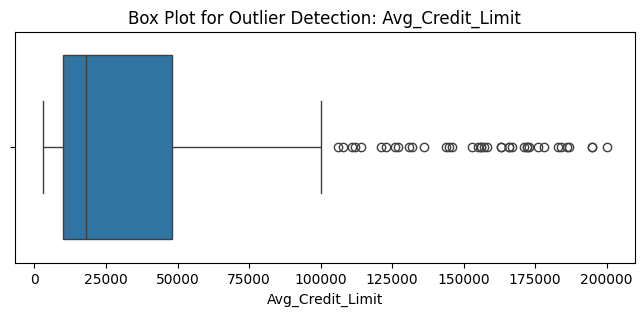

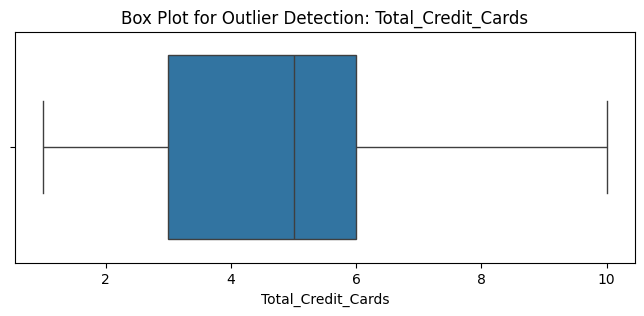

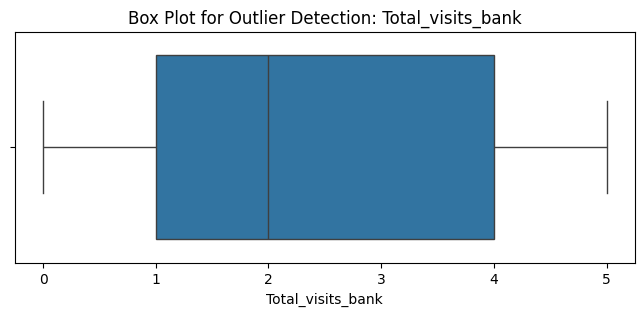

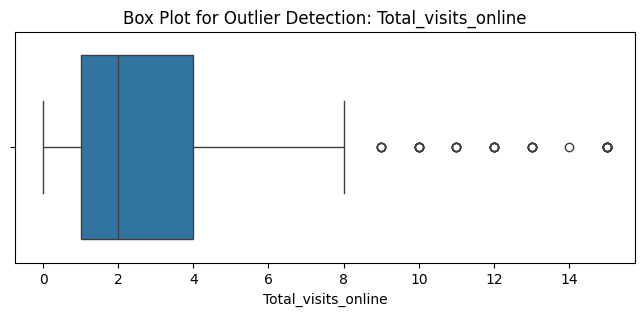

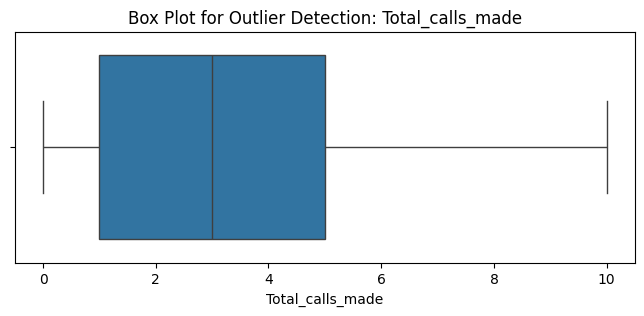

In [31]:
# Display box plots to visually detect outliers
for col in num_cols:
    # Create a new figure for each box plot
    plt.figure(figsize=(8, 3))
    # Create box plot for the selected column
    sns.boxplot(data=df_preprocessed, x=col)
    # Add title to the plot
    plt.title(f"Box Plot for Outlier Detection: {col}")
    # Display the plot
    plt.show()

In [32]:
# Define a function to calculate outliers using the IQR method
def find_outliers_iqr(data, column):
    # Calculate the first quartile
    Q1 = data[column].quantile(0.25)
    # Calculate the third quartile
    Q3 = data[column].quantile(0.75)
    # Calculate the interquartile range
    IQR = Q3 - Q1
    # Calculate lower bound for outliers
    lower_bound = Q1 - 1.5 * IQR
    # Calculate upper bound for outliers
    upper_bound = Q3 + 1.5 * IQR
    # Identify values below lower bound or above upper bound
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    # Return lower bound, upper bound, and number of outliers
    return lower_bound, upper_bound, outliers.shape[0]

In [33]:
# Check outliers for each numerical column using IQR method
for col in num_cols:
    # Calculate outlier bounds and count for the column
    lower, upper, count = find_outliers_iqr(df_preprocessed, col)
    # Print column name, lower bound, upper bound, and number of outliers
    print(f"{col}: Lower Bound = {lower}, Upper Bound = {upper}, Outliers = {count}")

Avg_Credit_Limit: Lower Bound = -47000.0, Upper Bound = 105000.0, Outliers = 39
Total_Credit_Cards: Lower Bound = -1.5, Upper Bound = 10.5, Outliers = 0
Total_visits_bank: Lower Bound = -3.5, Upper Bound = 8.5, Outliers = 0
Total_visits_online: Lower Bound = -3.5, Upper Bound = 8.5, Outliers = 37
Total_calls_made: Lower Bound = -5.0, Upper Bound = 11.0, Outliers = 0


###Outlier Treatment

In [34]:
# Create a copy of the preprocessed dataset for outlier treatment
df_outlier_treated = df_preprocessed.copy()

In [35]:
# Define a function to cap outliers using IQR bounds
def cap_outliers_iqr(data, column):
    # Calculate the first quartile
    Q1 = data[column].quantile(0.25)
    # Calculate the third quartile
    Q3 = data[column].quantile(0.75)
    # Calculate the interquartile range
    IQR = Q3 - Q1
    # Calculate lower bound for capping
    lower_bound = Q1 - 1.5 * IQR
    # Calculate upper bound for capping
    upper_bound = Q3 + 1.5 * IQR
    # Cap values below lower bound to lower bound
    data[column] = np.where(data[column] < lower_bound, lower_bound, data[column])
    # Cap values above upper bound to upper bound
    data[column] = np.where(data[column] > upper_bound, upper_bound, data[column])
    # Return the updated dataset
    return data

In [36]:
# Apply outlier capping to each numerical column
for col in num_cols:
    # Cap outliers in the selected column
    df_outlier_treated = cap_outliers_iqr(df_outlier_treated, col)

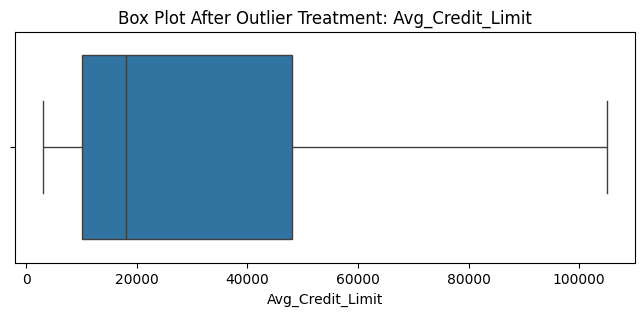

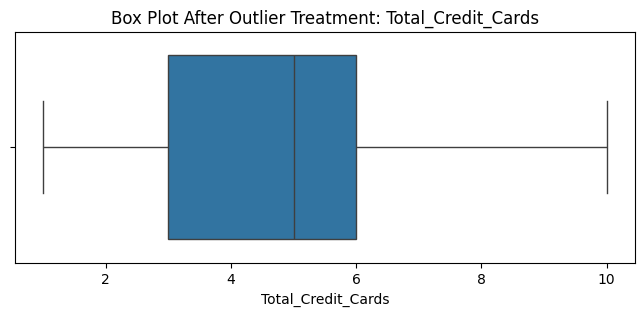

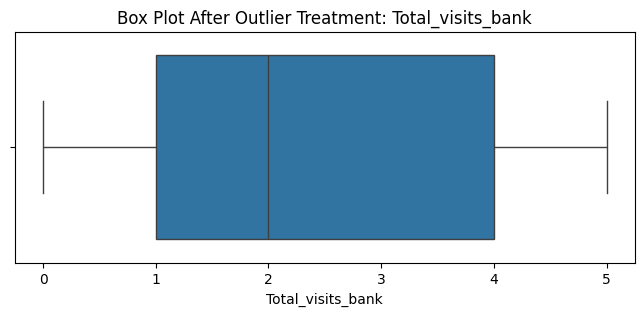

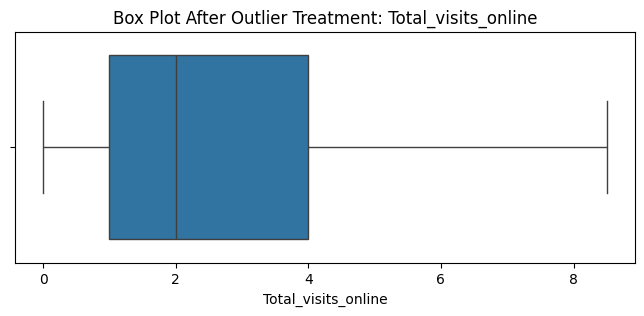

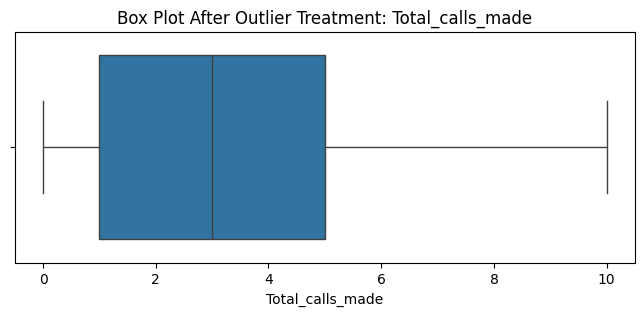

In [37]:
# Display box plots after outlier treatment
for col in num_cols:
    # Create a new figure for each box plot
    plt.figure(figsize=(8, 3))
    # Create box plot after outlier treatment
    sns.boxplot(data=df_outlier_treated, x=col)
    # Add title to the plot
    plt.title(f"Box Plot After Outlier Treatment: {col}")
    # Display the plot
    plt.show()

##Feature Engineering

In [38]:
# Create a copy of the outlier-treated dataset for feature engineering
df_feature_engineered = df_outlier_treated.copy()

In [39]:
# Create a new feature for total customer interactions with the bank
df_feature_engineered["Total_Interactions"] = (
    df_feature_engineered["Total_visits_bank"] +
    df_feature_engineered["Total_visits_online"] +
    df_feature_engineered["Total_calls_made"]
)

In [40]:
# Create a new feature for digital interaction ratio
df_feature_engineered["Digital_Interaction_Ratio"] = (
    df_feature_engineered["Total_visits_online"] /
    df_feature_engineered["Total_Interactions"]
)

In [41]:
# Replace missing or infinite values caused by division with zero
df_feature_engineered["Digital_Interaction_Ratio"] = (
    df_feature_engineered["Digital_Interaction_Ratio"]
    .replace([np.inf, -np.inf], 0)
    .fillna(0)
)

In [42]:
# Display first five rows after feature engineering
df_feature_engineered.head().T

,0,1,2,3,4
Avg_Credit_Limit,100000.0,50000.000000,50000.000,30000.000000,100000.00000
Total_Credit_Cards,2.0,3.000000,7.000,5.000000,6.00000
Total_visits_bank,1.0,0.000000,1.000,1.000000,0.00000
Total_visits_online,1.0,8.500000,3.000,1.000000,8.50000
Total_calls_made,0.0,9.000000,4.000,4.000000,3.00000
Total_Interactions,2.0,17.500000,8.000,6.000000,11.50000
Digital_Interaction_Ratio,0.5,0.485714,0.375,0.166667,0.73913


##Data Scaling

In [43]:
# Create a StandardScaler object
scaler = StandardScaler()

In [44]:
# Apply standard scaling to the feature-engineered dataset
scaled_data = scaler.fit_transform(df_feature_engineered)

In [45]:
# Convert the scaled array back into a DataFrame
scaled_df = pd.DataFrame(
    scaled_data,
    columns=df_feature_engineered.columns
)

In [46]:
# Display first five rows of the scaled dataset
scaled_df.head().T

,0,1,2,3,4
Avg_Credit_Limit,2.398942,0.643619,0.643619,-0.058511,2.398942
Total_Credit_Cards,-1.249225,-0.787585,1.058973,0.135694,0.597334
Total_visits_bank,-0.860451,-1.473731,-0.860451,-0.860451,-1.473731
Total_visits_online,-0.619767,2.705813,0.267054,-0.619767,2.705813
Total_calls_made,-1.251537,1.891859,0.145528,0.145528,-0.203739
Total_Interactions,-2.032908,2.902811,-0.122307,-0.759174,0.992210
Digital_Interaction_Ratio,1.118397,1.052764,0.544108,-0.413042,2.217039


In [47]:
# Check mean and standard deviation after scaling
scaled_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Avg_Credit_Limit,660.0,4.306320e-17,1.000758,-1.006385,-0.760640,-0.479788,0.573406,2.574474
Total_Credit_Cards,660.0,4.306320e-17,1.000758,-1.710864,-0.787585,0.135694,0.597334,2.443892
Total_visits_bank,660.0,-4.306320e-17,1.000758,-1.473731,-0.860451,-0.247170,0.979390,1.592670
Total_visits_online,660.0,-9.689219e-17,1.000758,-1.063178,-0.619767,-0.176357,0.710465,2.705813
Total_calls_made,660.0,-8.612639e-17,1.000758,-1.251537,-0.902271,-0.203739,0.494794,2.241125
Total_Interactions,660.0,-2.153160e-16,1.000758,-2.032908,-0.759174,-0.122307,0.514560,2.902811
Digital_Interaction_Ratio,660.0,1.614870e-17,1.000758,-1.178761,-0.604471,-0.030182,0.352678,3.415556


##Final Data Prepared for Clustering

In [48]:
# Create final dataset for clustering
X = scaled_df.copy()

In [49]:
# Display the shape of the final clustering dataset
X.shape

(660, 7)

In [50]:
# Display first five rows of the final clustering dataset
X.head().T

,0,1,2,3,4
Avg_Credit_Limit,2.398942,0.643619,0.643619,-0.058511,2.398942
Total_Credit_Cards,-1.249225,-0.787585,1.058973,0.135694,0.597334
Total_visits_bank,-0.860451,-1.473731,-0.860451,-0.860451,-1.473731
Total_visits_online,-0.619767,2.705813,0.267054,-0.619767,2.705813
Total_calls_made,-1.251537,1.891859,0.145528,0.145528,-0.203739
Total_Interactions,-2.032908,2.902811,-0.122307,-0.759174,0.992210
Digital_Interaction_Ratio,1.118397,1.052764,0.544108,-0.413042,2.217039


##Final Preprocessing Summary

- Missing values were checked and none were found.
- Duplicate rows were checked and none were found.
- Identifier columns `Sl_No` and `Customer Key` were removed.
- Outliers were detected using box plots and IQR method.
- Outliers were capped to reduce their effect without deleting records.
- New interaction-based features were created.
- Data was scaled using StandardScaler.
- Final scaled data is ready for K-means and hierarchical clustering.

##K-means Clustering

###Apply K-means Clustering

In [51]:
# Create an empty list to store inertia values
inertia = []
# Create an empty list to store silhouette scores
silhouette_scores = []
# Create a range of cluster numbers to test
k_values = range(2, 11)
# Loop through each value of k
for k in k_values:
        # Create KMeans model with current number of clusters
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        # Fit KMeans model on the scaled dataset
    kmeans.fit(X)
        # Append inertia value to the inertia list
    inertia.append(kmeans.inertia_)
        # Predict cluster labels for the scaled dataset
    cluster_labels = kmeans.labels_
        # Calculate silhouette score for the current k
    score = silhouette_score(X, cluster_labels)
        # Append silhouette score to the silhouette score list
    silhouette_scores.append(score)

##Plot the Elbow Curve

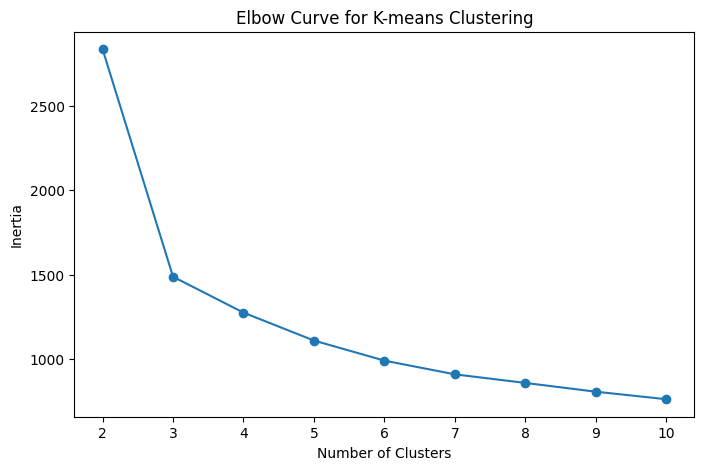

In [52]:
# Create a figure for the elbow curve
plt.figure(figsize=(8, 5))
# Plot k values against inertia values
plt.plot(k_values, inertia, marker="o")
# Add title to the plot
plt.title("Elbow Curve for K-means Clustering")
# Add x-axis label
plt.xlabel("Number of Clusters")
# Add y-axis label
plt.ylabel("Inertia")
# Display the plot
plt.show()

### Elbow Curve Observation

- The elbow curve helps identify the point where adding more clusters gives only a small improvement.
- Look for the point where the inertia starts decreasing slowly.
- In this dataset, the elbow is expected around 3 clusters,based on customer behavior patterns.

##Check Silhouette Scores

In [53]:
# Create a DataFrame to display k values and silhouette scores
silhouette_df = pd.DataFrame({
    "Number of Clusters": list(k_values),
    "Silhouette Score": silhouette_scores
})
# Display silhouette score DataFrame
silhouette_df

,Number of Clusters,Silhouette Score
0,2,0.413222
1,3,0.497719
2,4,0.339389
3,5,0.273674
4,6,0.272363
5,7,0.275726
6,8,0.262859
7,9,0.257124
8,10,0.255905


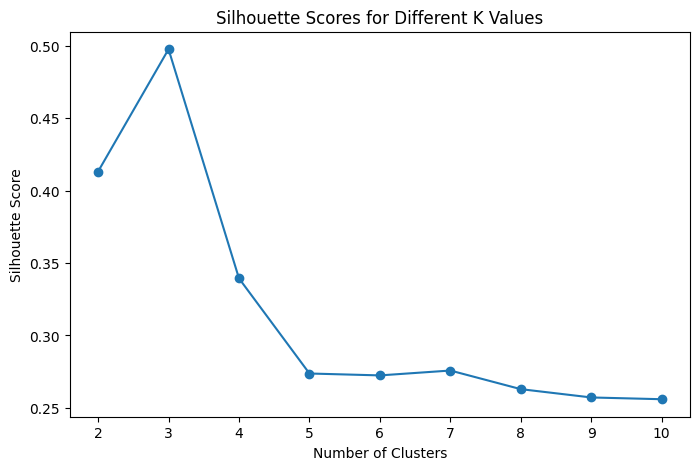

In [54]:
# Create a figure for silhouette score plot
plt.figure(figsize=(8, 5))
# Plot k values against silhouette scores
plt.plot(k_values, silhouette_scores, marker="o")
# Add title to the plot
plt.title("Silhouette Scores for Different K Values")
# Add x-axis label
plt.xlabel("Number of Clusters")
# Add y-axis label
plt.ylabel("Silhouette Score")
# Display the plot
plt.show()

###Silhouette Score Observation

- Silhouette score measures how well-separated the clusters are.
- A higher silhouette score indicates better-defined clusters.
- The value of `k` with a high silhouette score and good business interpretability should be selected.
- If `k = 3` gives a strong silhouette score and aligns with business understanding, we can use 3 clusters.

##Final K-means Model

In [55]:
# Create final KMeans model with 3 clusters
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
# Fit final KMeans model and predict cluster labels
kmeans_labels = kmeans_final.fit_predict(X)

In [56]:
# Add KMeans cluster labels to the feature-engineered dataset
df_feature_engineered["KMeans_Cluster"] = kmeans_labels

In [57]:
# Display first five rows with cluster labels
df_feature_engineered.head().T

,0,1,2,3,4
Avg_Credit_Limit,100000.0,50000.000000,50000.000,30000.000000,100000.00000
Total_Credit_Cards,2.0,3.000000,7.000,5.000000,6.00000
Total_visits_bank,1.0,0.000000,1.000,1.000000,0.00000
Total_visits_online,1.0,8.500000,3.000,1.000000,8.50000
Total_calls_made,0.0,9.000000,4.000,4.000000,3.00000
Total_Interactions,2.0,17.500000,8.000,6.000000,11.50000
Digital_Interaction_Ratio,0.5,0.485714,0.375,0.166667,0.73913
KMeans_Cluster,1.0,2.000000,1.000,1.000000,0.00000


In [58]:
# Check number of customers in each KMeans cluster
df_feature_engineered["KMeans_Cluster"].value_counts().sort_index()

,count
KMeans_Cluster,
0,50
1,388
2,222


##Cluster Profiling

In [59]:
# Calculate average values of each feature for every KMeans cluster
kmeans_cluster_profile = df_feature_engineered.groupby("KMeans_Cluster").mean().T
# Display KMeans cluster profile
kmeans_cluster_profile

KMeans_Cluster,0,1,2
Avg_Credit_Limit,102660.00000,33664.948454,12184.684685
Total_Credit_Cards,8.74000,5.505155,2.400901
Total_visits_bank,0.60000,3.476804,0.932432
Total_visits_online,8.18000,0.984536,3.565315
Total_calls_made,1.08000,2.002577,6.909910
Total_Interactions,9.86000,6.463918,11.407658
Digital_Interaction_Ratio,0.83764,0.147904,0.315618


In [60]:
# Calculate median values of each feature for every KMeans cluster
kmeans_cluster_profile_median = df_feature_engineered.groupby("KMeans_Cluster").median().T
# Display median-based KMeans cluster profile
kmeans_cluster_profile_median

KMeans_Cluster,0,1,2
Avg_Credit_Limit,105000.000000,31000.000000,12000.000000
Total_Credit_Cards,9.000000,6.000000,2.000000
Total_visits_bank,1.000000,3.000000,1.000000
Total_visits_online,8.500000,1.000000,4.000000
Total_calls_made,1.000000,2.000000,7.000000
Total_Interactions,9.750000,6.000000,11.000000
Digital_Interaction_Ratio,0.809524,0.166667,0.310096


In [61]:
# Create a copy of cluster profile for visualization
cluster_profile_plot = kmeans_cluster_profile.copy()

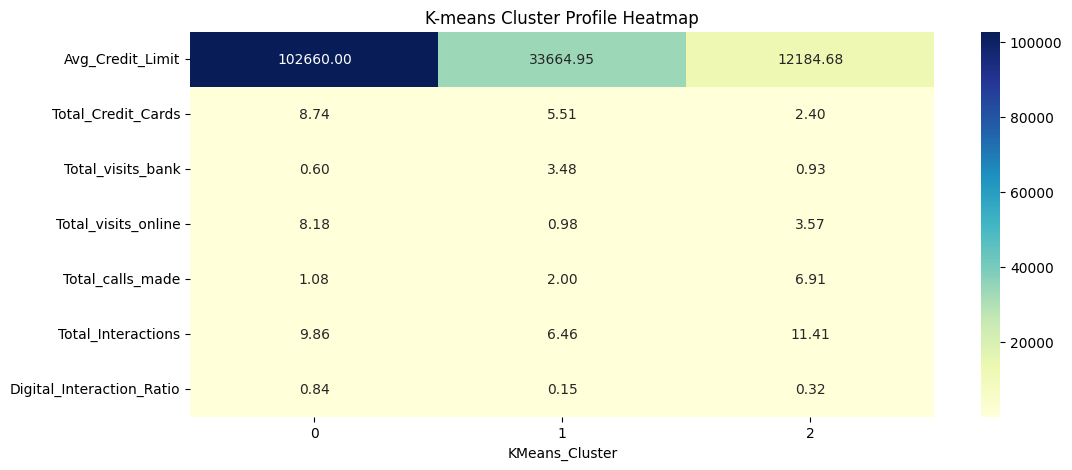

In [62]:
# Create a heatmap to visualize cluster profiles
plt.figure(figsize=(12, 5))
# Plot heatmap of cluster average values
sns.heatmap(cluster_profile_plot, annot=True, cmap="YlGnBu", fmt=".2f")
# Add title to heatmap
plt.title("K-means Cluster Profile Heatmap")
# Display the plot
plt.show()

##Visualize K-means Clusters Using PCA

In [63]:
# Create PCA object with two components
pca = PCA(n_components=2)

In [64]:
# Transform scaled dataset into two principal components
pca_data = pca.fit_transform(X)

In [65]:
# Create a DataFrame for PCA results
pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"]
)

In [66]:
# Add KMeans cluster labels to PCA DataFrame
pca_df["KMeans_Cluster"] = kmeans_labels

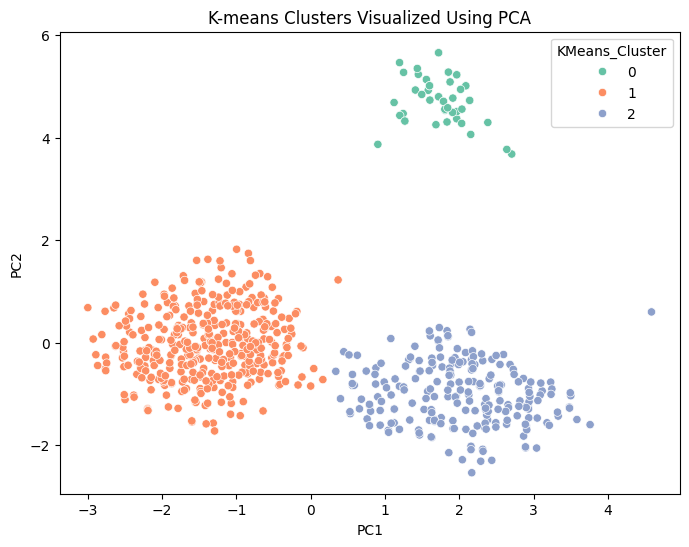

In [67]:
# Create figure for PCA cluster visualization
plt.figure(figsize=(8, 6))
# Create scatter plot for PCA components colored by KMeans cluster
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    palette="Set2"
)
# Add title to the plot
plt.title("K-means Clusters Visualized Using PCA")
# Display the plot
plt.show()

##K-means Clustering Summary

- K-means clustering was applied for different values of `k`.
- The elbow curve was used to study inertia values.
- Silhouette scores were checked to evaluate cluster quality.
- Based on the elbow curve, silhouette scores, and business interpretability, 3 clusters were selected.
- Cluster profiling was done using mean and median values.
- PCA visualization was used to display the clusters in two dimensions.
- The clusters show meaningful customer groups based on credit limit, number of cards, and interaction behavior.

##Hierarchical Clustering

##Apply Hierarchical Clustering with Different Linkage Methods

In [68]:
# Create a list of linkage methods to compare
linkage_methods = ["single", "complete", "average", "ward"]

In [69]:
# Create an empty dictionary to store linkage matrices
linkage_matrices = {}
# Create an empty dictionary to store cophenetic correlation values
cophenetic_scores = {}

In [70]:
# Loop through each linkage method
for method in linkage_methods:
        # Create linkage matrix using the selected linkage method
    linkage_matrix = linkage(X, method=method)
        # Store the linkage matrix in the dictionary
    linkage_matrices[method] = linkage_matrix
        # Calculate cophenetic correlation for the linkage method
    coph_corr, coph_dist = cophenet(linkage_matrix, pdist(X))
        # Store cophenetic correlation score in the dictionary
    cophenetic_scores[method] = coph_corr

##Plot Dendrograms for Each Linkage Method

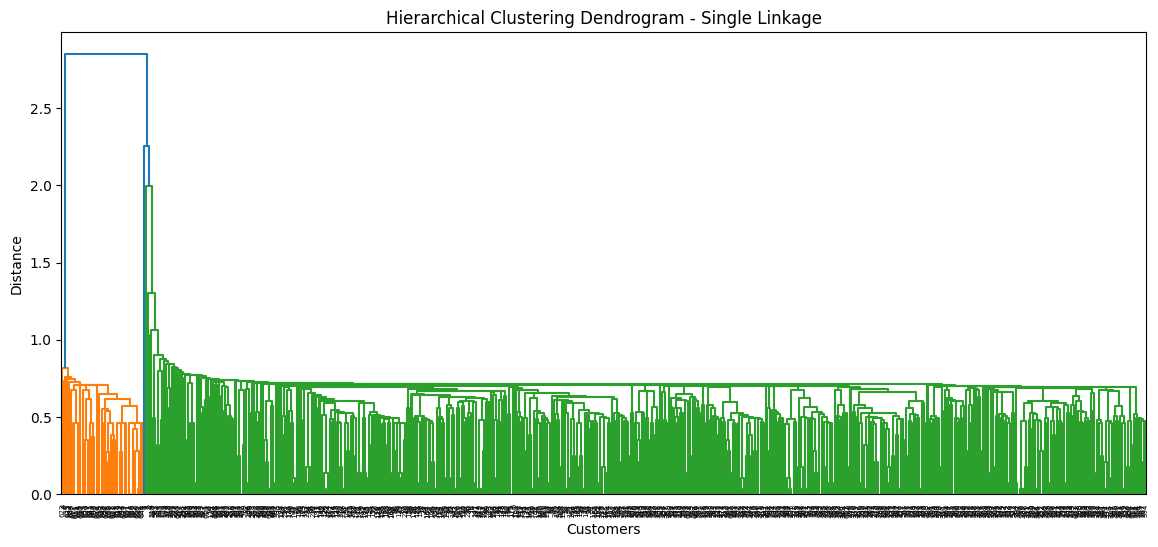

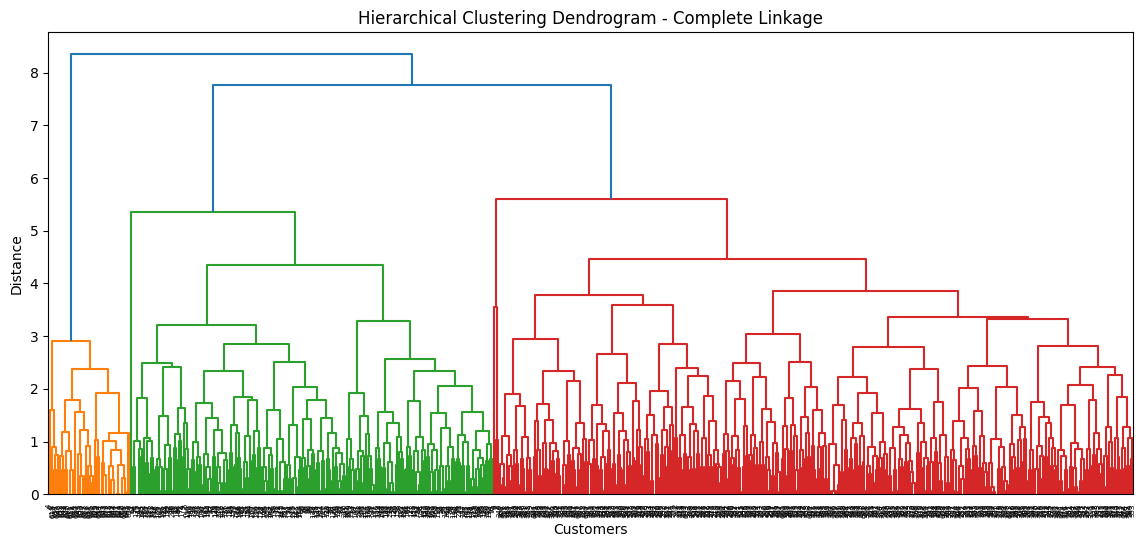

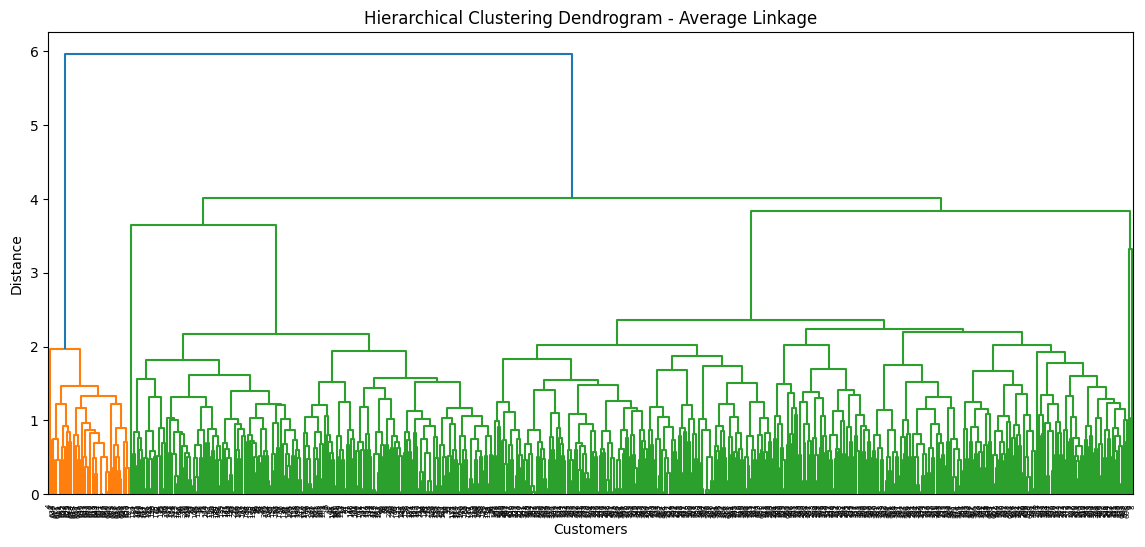

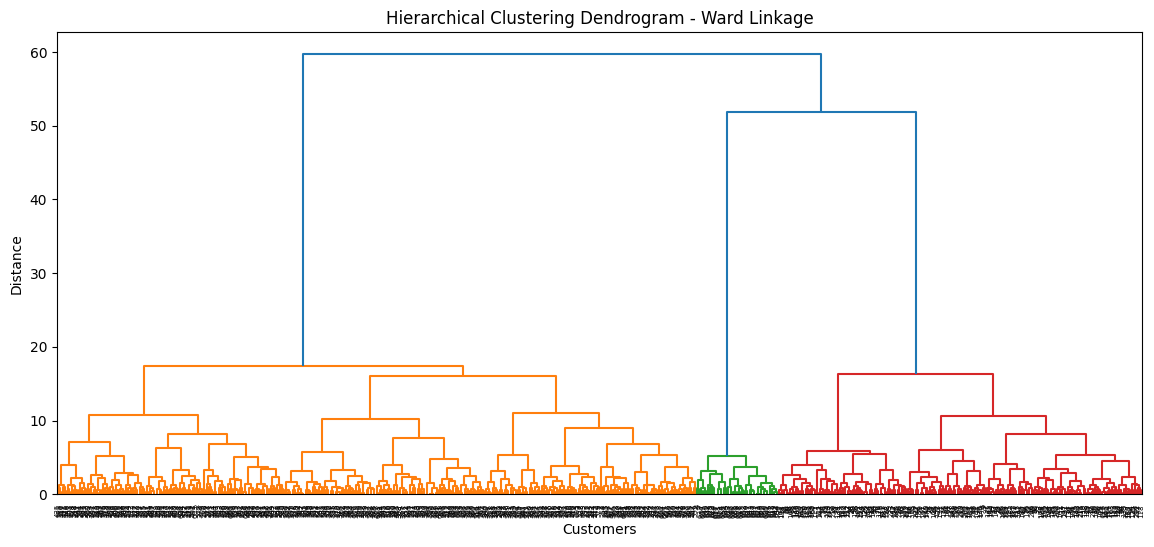

In [71]:
# Loop through each linkage method
for method in linkage_methods:
        # Create a new figure for dendrogram
    plt.figure(figsize=(14, 6))
        # Plot dendrogram for the selected linkage method
    dendrogram(linkage_matrices[method])
        # Add title to the dendrogram
    plt.title(f"Hierarchical Clustering Dendrogram - {method.capitalize()} Linkage")
      # Add x-axis label
    plt.xlabel("Customers")
      # Add y-axis label
    plt.ylabel("Distance")
        # Display the dendrogram
    plt.show()

##Check Cophenetic Correlation for Each Linkage Method

In [72]:
# Convert cophenetic correlation dictionary into a DataFrame
cophenetic_df = pd.DataFrame({
    "Linkage Method": list(cophenetic_scores.keys()),
    "Cophenetic Correlation": list(cophenetic_scores.values())
})

In [73]:
# Sort cophenetic correlation values in descending order
cophenetic_df = cophenetic_df.sort_values(
    by="Cophenetic Correlation",
    ascending=False
)

In [74]:
# Display cophenetic correlation scores
cophenetic_df

,Linkage Method,Cophenetic Correlation
2,average,0.883420
1,complete,0.816317
3,ward,0.764090
0,single,0.674087


###Cophenetic Correlation Observation

- Cophenetic correlation measures how well the dendrogram preserves the original pairwise distances between observations.
- A higher cophenetic correlation value indicates a better hierarchical clustering structure.
- We compare `single`, `complete`, `average`, and `ward` linkage methods.
- The linkage method with a higher cophenetic correlation and interpretable dendrogram should be preferred.

##Figure Out the Appropriate Number of Clusters

From the dendrograms, we look for the largest vertical distance that is not crossed by a horizontal cluster cut line.

Based on the K-means result and likely dendrogram separation, we will try 3 clusters for hierarchical clustering first.

This also helps us compare K-means and hierarchical clustering using the same number of clusters.

##Build Final Hierarchical Clustering Model

In [75]:
# Create final hierarchical clustering model with 3 clusters
hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

In [76]:
# Fit the hierarchical clustering model and predict cluster labels
hierarchical_labels = hierarchical_model.fit_predict(X)

In [77]:
# Add hierarchical cluster labels to the feature-engineered dataset
df_feature_engineered["Hierarchical_Cluster"] = hierarchical_labels

In [78]:
# Display first five rows with hierarchical cluster labels
df_feature_engineered.head().T

,0,1,2,3,4
Avg_Credit_Limit,100000.0,50000.000000,50000.000,30000.000000,100000.00000
Total_Credit_Cards,2.0,3.000000,7.000,5.000000,6.00000
Total_visits_bank,1.0,0.000000,1.000,1.000000,0.00000
Total_visits_online,1.0,8.500000,3.000,1.000000,8.50000
Total_calls_made,0.0,9.000000,4.000,4.000000,3.00000
Total_Interactions,2.0,17.500000,8.000,6.000000,11.50000
Digital_Interaction_Ratio,0.5,0.485714,0.375,0.166667,0.73913
KMeans_Cluster,1.0,2.000000,1.000,1.000000,0.00000
Hierarchical_Cluster,0.0,1.000000,0.000,0.000000,2.00000


In [79]:
# Check number of customers in each hierarchical cluster
df_feature_engineered["Hierarchical_Cluster"].value_counts().sort_index()

,count
Hierarchical_Cluster,
0,389
1,221
2,50


##Cluster Profiling

In [80]:
# Calculate mean values of features for each hierarchical cluster
hierarchical_cluster_profile = df_feature_engineered.groupby("Hierarchical_Cluster").mean()

In [81]:
# Display hierarchical cluster profile using mean values
hierarchical_cluster_profile.T

Hierarchical_Cluster,0,1,2
Avg_Credit_Limit,33591.259640,12217.194570,102660.00000
Total_Credit_Cards,5.496144,2.402715,8.74000
Total_visits_bank,3.467866,0.936652,0.60000
Total_visits_online,0.987147,3.572398,8.18000
Total_calls_made,2.002571,6.932127,1.08000
Total_Interactions,6.457584,11.441176,9.86000
Digital_Interaction_Ratio,0.148809,0.314783,0.83764
KMeans_Cluster,1.002571,2.000000,0.00000


In [82]:
# Calculate median values of features for each hierarchical cluster
hierarchical_cluster_profile_median = df_feature_engineered.groupby("Hierarchical_Cluster").median()

In [83]:
# Display hierarchical cluster profile using median values
hierarchical_cluster_profile_median.T

Hierarchical_Cluster,0,1,2
Avg_Credit_Limit,31000.000000,12000.000000,105000.000000
Total_Credit_Cards,6.000000,2.000000,9.000000
Total_visits_bank,3.000000,1.000000,1.000000
Total_visits_online,1.000000,4.000000,8.500000
Total_calls_made,2.000000,7.000000,1.000000
Total_Interactions,6.000000,11.000000,9.750000
Digital_Interaction_Ratio,0.166667,0.307692,0.809524
KMeans_Cluster,1.000000,2.000000,0.000000


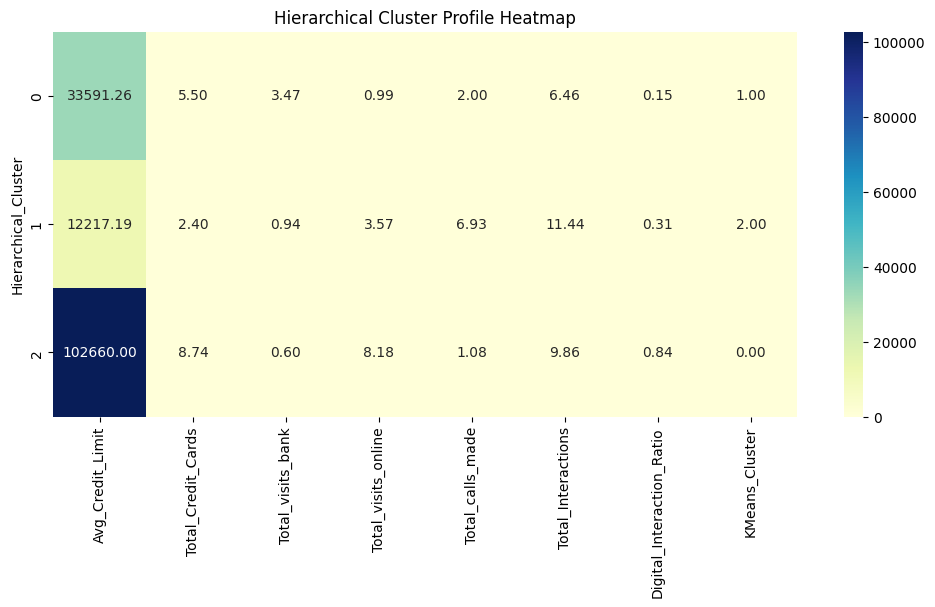

In [84]:
# Create a figure for hierarchical cluster profile heatmap
plt.figure(figsize=(12, 5))
# Plot heatmap of hierarchical cluster average values
sns.heatmap(
    hierarchical_cluster_profile,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)
# Add title to the heatmap
plt.title("Hierarchical Cluster Profile Heatmap")
# Display the heatmap
plt.show()

In [85]:
# Create a PCA object with 2 components for 2D visualization
pca = PCA(n_components=2)
# Fit PCA on the scaled dataset X and transform it into two principal components
pca_data = pca.fit_transform(X)
# Create a DataFrame using the two PCA components
hierarchical_pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"]
)
# Add hierarchical cluster labels to the PCA DataFrame
hierarchical_pca_df["Hierarchical_Cluster"] = hierarchical_labels
# Display the first five rows of the PCA DataFrame
hierarchical_pca_df.head()

,PC1,PC2,Hierarchical_Cluster
0,-0.837416,1.742524,0
1,4.587136,0.600131,1
2,0.369636,1.224837,0
3,-0.376957,-0.280925,0
4,2.706577,3.679005,2


In [86]:
# Create a DataFrame for PCA results if not already created
hierarchical_pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"]
)

In [87]:
# Add hierarchical cluster labels to PCA DataFrame
hierarchical_pca_df["Hierarchical_Cluster"] = hierarchical_labels

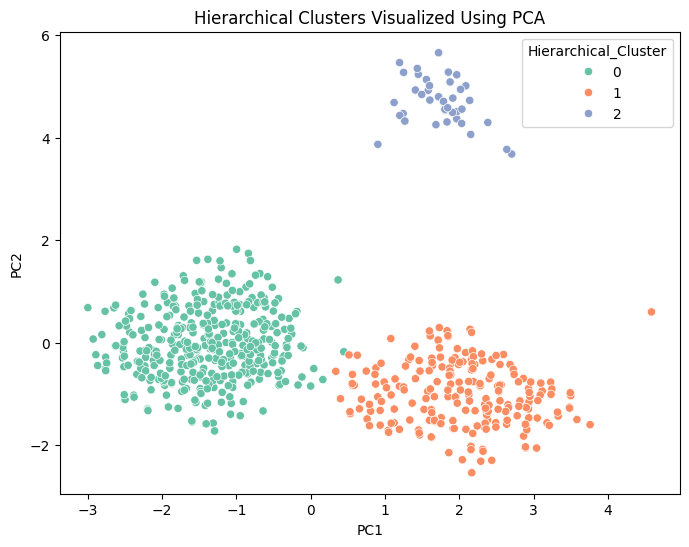

In [88]:
# Create figure for PCA visualization
plt.figure(figsize=(8, 6))
# Create scatter plot of PCA components colored by hierarchical clusters
sns.scatterplot(
    data=hierarchical_pca_df,
    x="PC1",
    y="PC2",
    hue="Hierarchical_Cluster",
    palette="Set2"
)
# Add title to the plot
plt.title("Hierarchical Clusters Visualized Using PCA")
# Display the plot
plt.show()

##Hierarchical Clustering Summary

- Hierarchical clustering was applied using different linkage methods.
- Dendrograms were plotted for `single`, `complete`, `average`, and `ward` linkage.
- Cophenetic correlation was calculated to compare linkage methods.
- The appropriate number of clusters was selected by studying dendrogram separation and business interpretability.
- A final hierarchical clustering model was built using 3 clusters.
- Cluster profiling was performed using mean and median values.
- PCA visualization was used to view the hierarchical clusters in two dimensions.
- The clusters show meaningful customer groups based on credit limit, credit card ownership, and customer interaction behavior.

##K-means vs Hierarchical Clustering Comparison

##Compare Cluster Labels from Both Methods

In [89]:
# Create a comparison DataFrame with K-means and hierarchical cluster labels
cluster_comparison = pd.DataFrame({
    "KMeans_Cluster": kmeans_labels,
    "Hierarchical_Cluster": hierarchical_labels
})

In [90]:
# Display the first five rows of the comparison DataFrame
cluster_comparison.head()

,KMeans_Cluster,Hierarchical_Cluster
0,1,0
1,2,1
2,1,0
3,1,0
4,0,2


In [91]:
# Create a cross-tabulation to compare how customers are assigned by both algorithms
comparison_table = pd.crosstab(
    cluster_comparison["KMeans_Cluster"],
    cluster_comparison["Hierarchical_Cluster"]
)

In [92]:
# Display the comparison table
comparison_table

Hierarchical_Cluster,0,1,2
KMeans_Cluster,,,
0,0,0,50
1,388,0,0
2,1,221,0


##Compare Cluster Sizes

In [93]:
# Count number of customers in each K-means cluster
kmeans_cluster_sizes = df_feature_engineered["KMeans_Cluster"].value_counts().sort_index()

In [94]:
# Display K-means cluster sizes
kmeans_cluster_sizes

,count
KMeans_Cluster,
0,50
1,388
2,222


In [95]:
# Count number of customers in each hierarchical cluster
hierarchical_cluster_sizes = df_feature_engineered["Hierarchical_Cluster"].value_counts().sort_index()

In [96]:
# Display hierarchical cluster sizes
hierarchical_cluster_sizes

,count
Hierarchical_Cluster,
0,389
1,221
2,50


In [97]:
# Create a DataFrame to compare cluster sizes
cluster_size_comparison = pd.DataFrame({
    "KMeans Cluster Size": kmeans_cluster_sizes,
    "Hierarchical Cluster Size": hierarchical_cluster_sizes
})

In [98]:
# Display cluster size comparison
cluster_size_comparison

,KMeans Cluster Size,Hierarchical Cluster Size
0,50,389
1,388,221
2,222,50


<Figure size 800x500 with 0 Axes>

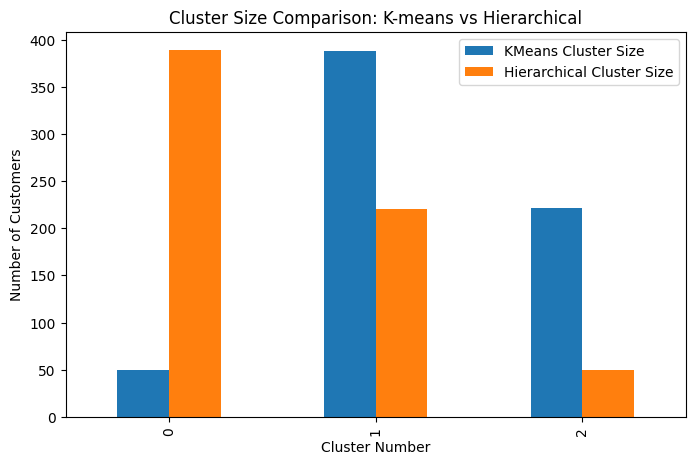

In [99]:
# Create a figure for cluster size comparison
plt.figure(figsize=(8, 5))
# Plot cluster size comparison as a bar chart
cluster_size_comparison.plot(kind="bar", figsize=(8, 5))
# Add title to the plot
plt.title("Cluster Size Comparison: K-means vs Hierarchical")
# Add x-axis label
plt.xlabel("Cluster Number")
# Add y-axis label
plt.ylabel("Number of Customers")
# Display legend
plt.legend()
# Display the plot
plt.show()

##Compare Cluster Profiles

In [100]:
# Calculate K-means cluster profile using mean values
kmeans_profile = df_feature_engineered.groupby("KMeans_Cluster").mean()

In [101]:
# Display K-means cluster profile
kmeans_profile.T

KMeans_Cluster,0,1,2
Avg_Credit_Limit,102660.00000,33664.948454,12184.684685
Total_Credit_Cards,8.74000,5.505155,2.400901
Total_visits_bank,0.60000,3.476804,0.932432
Total_visits_online,8.18000,0.984536,3.565315
Total_calls_made,1.08000,2.002577,6.909910
Total_Interactions,9.86000,6.463918,11.407658
Digital_Interaction_Ratio,0.83764,0.147904,0.315618
Hierarchical_Cluster,2.00000,0.000000,0.995495


In [102]:
# Calculate hierarchical cluster profile using mean values
hierarchical_profile = df_feature_engineered.groupby("Hierarchical_Cluster").mean()

In [103]:
# Display hierarchical cluster profile
hierarchical_profile.T

Hierarchical_Cluster,0,1,2
Avg_Credit_Limit,33591.259640,12217.194570,102660.00000
Total_Credit_Cards,5.496144,2.402715,8.74000
Total_visits_bank,3.467866,0.936652,0.60000
Total_visits_online,0.987147,3.572398,8.18000
Total_calls_made,2.002571,6.932127,1.08000
Total_Interactions,6.457584,11.441176,9.86000
Digital_Interaction_Ratio,0.148809,0.314783,0.83764
KMeans_Cluster,1.002571,2.000000,0.00000


##Visual Comparison of Cluster Profiles

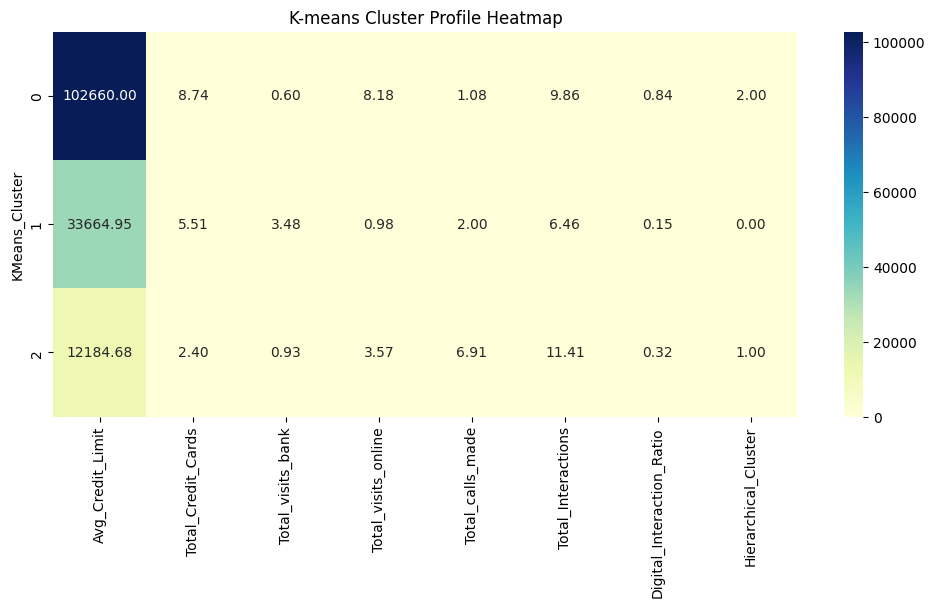

In [104]:
# Create a figure for K-means cluster profile heatmap
plt.figure(figsize=(12, 5))
# Plot K-means cluster profile heatmap
sns.heatmap(
    kmeans_profile,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)
# Add title to the heatmap
plt.title("K-means Cluster Profile Heatmap")
# Display the heatmap
plt.show()

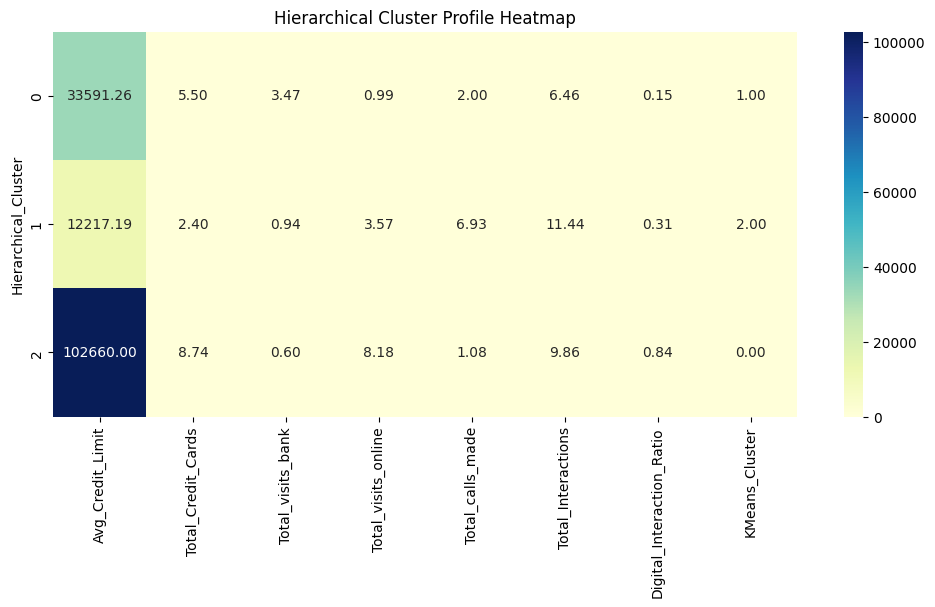

In [105]:
# Create a figure for hierarchical cluster profile heatmap
plt.figure(figsize=(12, 5))
# Plot hierarchical cluster profile heatmap
sns.heatmap(
    hierarchical_profile,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)
# Add title to the heatmap
plt.title("Hierarchical Cluster Profile Heatmap")
#Display the heatmap
plt.show()

##Compare Model Evaluation Metrics

In [106]:
# Calculate silhouette score for final K-means clustering
kmeans_silhouette = silhouette_score(X, kmeans_labels)

In [107]:
# Calculate silhouette score for final hierarchical clustering
hierarchical_silhouette = silhouette_score(X, hierarchical_labels)

In [108]:
# Create a DataFrame to compare silhouette scores
model_score_comparison = pd.DataFrame({
    "Model": ["K-means Clustering", "Hierarchical Clustering"],
    "Silhouette Score": [kmeans_silhouette, hierarchical_silhouette]
})

In [109]:
# Display silhouette score comparison
model_score_comparison

,Model,Silhouette Score
0,K-means Clustering,0.497719
1,Hierarchical Clustering,0.497425


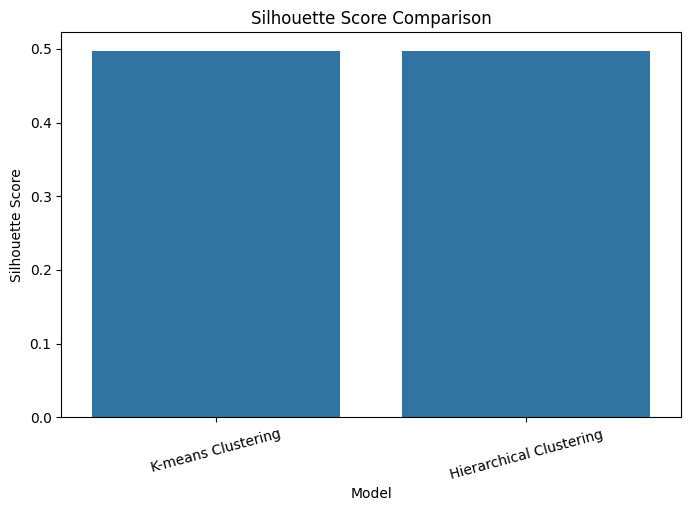

In [110]:
# Create a figure for silhouette score comparison
plt.figure(figsize=(8, 5))
# Create bar plot for silhouette scores
sns.barplot(
    data=model_score_comparison,
    x="Model",
    y="Silhouette Score"
)
# Add title to the plot
plt.title("Silhouette Score Comparison")
# Rotate x-axis labels for better readability
plt.xticks(rotation=15)
# Display the plot
plt.show()

##Final Comparison Observations

- Both K-means and hierarchical clustering were used to segment customers.
- K-means uses centroid-based clustering and works well when clusters are compact and separated.
- Hierarchical clustering creates a tree-like structure and helps visualize customer grouping through dendrograms.
- Both methods identify similar broad customer groups:
  - Customers with lower credit limits and higher service calls
  - Customers with moderate credit limits and more branch visits
  - Customers with higher credit limits, more cards, and higher online activity
- K-means is easier to scale and faster for larger datasets.
- Hierarchical clustering is more useful for visualizing nested relationships between customers.
- The final choice should be based on silhouette score, cluster interpretability, and business usefulness.

##Recommended Clustering Method

K-means clustering can be selected as the final segmentation method if it provides a good silhouette score and clear business interpretation.

Reasons:
- It is simple and easy to explain to business stakeholders.
- It produces clear cluster assignments.
- It is efficient and scalable for customer segmentation problems.
- The resulting clusters are easy to profile and use for marketing campaigns.

However, hierarchical clustering is also useful because dendrograms help understand how customer groups are formed.